In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.layers import Dense, SimpleRNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

2024-04-13 17:50:15.459653: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-13 17:50:15.687863: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/kaan/summer_ws/devel/lib:/home/kaan/rob_ws/devel/lib:/home/kaan/aria_ws/devel/lib:/home/kaan/catkin_ws/devel/lib:/opt/ros/noetic/lib:/opt/ros/noetic/lib/x86_64-linux-gnu:/home/kaan/.local/lib/python3.9/site-packages/nvidia/cudnn/lib:/usr/local/cuda-12/lib64
2024-04-13 17:50:15.687901: I tensorflow/compiler/xla/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do n

In [2]:
df = pd.read_csv('gazebo_dataset_synced.csv')

In [3]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
95865,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [4]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
95865,-0.154206,-0.471443,0.801403
95866,-0.154157,-0.471496,0.801452
95867,-0.154109,-0.471548,0.801501
95868,-0.154060,-0.471601,0.801549


In [5]:
X.shape

(95870, 3)

In [6]:
xscaler = MinMaxScaler()
yscaler = MinMaxScaler()
X_s = xscaler.fit_transform(X)
y_s = yscaler.fit_transform(y)

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

In [8]:
# Reshape input to be 3D [samples, timesteps, features]
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

In [9]:
X_train.shape

(76696, 1, 3)

In [10]:
# Define your RNN model architecture
model = Sequential()
model.add(SimpleRNN(128, activation='relu', input_shape=(1, 3)))
model.add(Dense(128, activation='relu'))
model.add(Dense(32, activation='linear'))
model.add(Dense(7))

# Compile model
model.compile(optimizer='adam', loss='mse', metrics='mae')

# Train model
history = model.fit(X_train, y_train, epochs=200, validation_split=0.2, verbose=1)

2024-04-13 17:50:19.326333: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-04-13 17:50:19.326713: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/kaan/summer_ws/devel/lib:/home/kaan/rob_ws/devel/lib:/home/kaan/aria_ws/devel/lib:/home/kaan/catkin_ws/devel/lib:/opt/ros/noetic/lib:/opt/ros/noetic/lib/x86_64-linux-gnu:/home/kaan/.local/lib/python3.9/site-packages/nvidia/cudnn/lib:/usr/local/cuda-12/lib64
2024-04-13 17:50:19.326858: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory; LD

Epoch 1/200
1918/1918 [==============================] - 9s 3ms/step - loss: 0.0332 - mae: 0.1233 - val_loss: 0.0275 - val_mae: 0.1151
Epoch 2/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0238 - mae: 0.1017 - val_loss: 0.0214 - val_mae: 0.0933
Epoch 3/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0205 - mae: 0.0928 - val_loss: 0.0195 - val_mae: 0.0894
Epoch 4/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0187 - mae: 0.0880 - val_loss: 0.0196 - val_mae: 0.0916
Epoch 5/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0172 - mae: 0.0837 - val_loss: 0.0162 - val_mae: 0.0808
Epoch 6/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0158 - mae: 0.0796 - val_loss: 0.0158 - val_mae: 0.0793
Epoch 7/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0149 - mae: 0.0769 - val_loss: 0.0150 - val_mae: 0.0782
Epoch 8/200
1918/1918 [==============================] 

1918/1918 [==============================] - 6s 3ms/step - loss: 0.0053 - mae: 0.0424 - val_loss: 0.0063 - val_mae: 0.0464
Epoch 122/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0054 - mae: 0.0425 - val_loss: 0.0057 - val_mae: 0.0433
Epoch 123/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0053 - mae: 0.0423 - val_loss: 0.0054 - val_mae: 0.0433
Epoch 124/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0054 - mae: 0.0424 - val_loss: 0.0057 - val_mae: 0.0452
Epoch 125/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0053 - mae: 0.0423 - val_loss: 0.0054 - val_mae: 0.0424
Epoch 126/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0053 - mae: 0.0422 - val_loss: 0.0056 - val_mae: 0.0439
Epoch 127/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0053 - mae: 0.0422 - val_loss: 0.0059 - val_mae: 0.0447
Epoch 128/200
1918/1918 [==============================

Epoch 181/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0048 - mae: 0.0403 - val_loss: 0.0052 - val_mae: 0.0414
Epoch 182/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0049 - mae: 0.0402 - val_loss: 0.0048 - val_mae: 0.0402
Epoch 183/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0048 - mae: 0.0403 - val_loss: 0.0050 - val_mae: 0.0406
Epoch 184/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0048 - mae: 0.0402 - val_loss: 0.0049 - val_mae: 0.0404
Epoch 185/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0048 - mae: 0.0402 - val_loss: 0.0049 - val_mae: 0.0404
Epoch 186/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0048 - mae: 0.0400 - val_loss: 0.0051 - val_mae: 0.0414
Epoch 187/200
1918/1918 [==============================] - 6s 3ms/step - loss: 0.0048 - mae: 0.0403 - val_loss: 0.0048 - val_mae: 0.0399
Epoch 188/200
1918/1918 [================

In [11]:
# Evaluate your model
loss = model.evaluate(X_test, y_test, verbose=0)
print('Test loss:', loss)

Test loss: [0.004802970681339502, 0.040580060333013535]


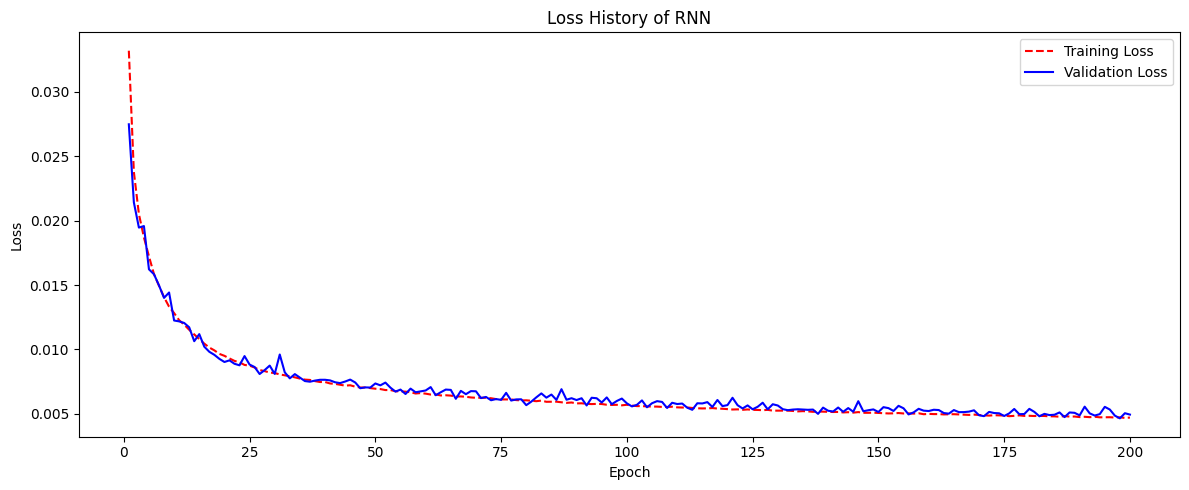

In [12]:
# Get training and validation loss histories
training_loss = history.history['loss']
validation_loss = history.history['val_loss']  # Corrected to 'val_loss'

# Create count of the number of epochs
epoch_count = range(1, len(training_loss)+1)

plt.figure(figsize=(12, 5))

#plt.subplot(111)
plt.plot(epoch_count, training_loss, 'r--')
plt.plot(epoch_count, validation_loss, 'b-')
plt.legend(['Training Loss', 'Validation Loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss History of RNN')

plt.tight_layout()
plt.show()

In [13]:
# Use your model to predict joint angles from x, y, z coordinates
x_new = np.array([[0.5, 0, 0.4]])  # New x, y, z coordinates
x_new = xscaler.transform(x_new)  # Normalize
x_new = x_new.reshape((1, 1, 3))  # Reshape
y_new = model.predict(x_new)  # Predict
print('Predicted joint angles:', y_new)

/home/kaan/.local/lib/python3.8/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


1/1 [==============================] - 0s 320ms/step
Predicted joint angles: [[ 0.9522339   0.5950981   0.93463814  0.18469444 -0.16710635  0.946724
   0.8085355 ]]


In [14]:
np.rad2deg(yscaler.inverse_transform(y_new))

array([[ 148.83742  ,   17.875662 ,  122.14222  ,  107.67588  ,
        -224.61159  ,   -2.9817276,  -43.18842  ]], dtype=float32)

In [15]:
tf.saved_model.save(model, 'RNN_model')


INFO:tensorflow:Assets written to: RNN_model/assets


INFO:tensorflow:Assets written to: RNN_model/assets


-
-